# 02 · Formatos de datos y pandas

Los datos llegan como CSV, JSON, hojas de cálculo, bases de datos o archivos columnares, y el formato en el
que los guardas decide cuánto ocupan, lo rápido que se cargan y qué puede salir mal. Este módulo presenta
pandas, la herramienta estándar para tablas en Python, y después mide los formatos habituales con los mismos
datos.

**Aprenderás**
1. El `DataFrame` de pandas: crear, inspeccionar, seleccionar, filtrar, agrupar
2. Leer y escribir CSV, JSON, Excel, Parquet, Feather, SQLite, YAML y pickle
3. Qué formato elegir, con mediciones: tamaño del archivo, tiempo de escritura y de lectura, tipos que se conservan
4. Trampas: codificaciones, fechas, tipos perdidos en CSV y por qué nunca debes cargar un pickle que no sea de confianza

## 1. El DataFrame de pandas
Una tabla bidimensional con etiquetas: las columnas tienen nombre y tipo, y las filas un índice.

In [1]:
import pandas as pd

df = pd.DataFrame({
    "name": ["Alice", "Bob", "Charlie", "Diana"],
    "age": [30, 25, 35, 28],
    "city": ["Berlin", "Paris", "Berlin", "Madrid"],
    "salary": [62_000, 48_000, 75_000, 51_000],
})
print(df.shape)
print(df.dtypes)
df.head(3)

(4, 4)
name      object
age        int64
city      object
salary     int64
dtype: object


,name,age,city,salary
0,Alice,30,Berlin,62000
1,Bob,25,Paris,48000
2,Charlie,35,Berlin,75000


In [2]:
print(df["name"].tolist())            # una columna (una Series)
print(df.loc[0, "city"])               # por etiqueta
print(df.iloc[1].to_dict())            # por posición
df[(df["age"] > 26) & (df["city"] == "Berlin")]   # filtrado booleano

['Alice', 'Bob', 'Charlie', 'Diana']
Berlin
{'name': 'Bob', 'age': 25, 'city': 'Paris', 'salary': 48000}


,name,age,city,salary
0,Alice,30,Berlin,62000
2,Charlie,35,Berlin,75000


In [3]:
df["senior"] = df["age"] >= 30                     # columna nueva
summary = df.groupby("city").agg(people=("name", "count"), mean_salary=("salary", "mean"))
print(summary)
df.describe()

        people  mean_salary
city                       
Berlin       2      68500.0
Madrid       1      51000.0
Paris        1      48000.0


,age,salary
count,4.000000,4.000000
mean,29.500000,59000.000000
std,4.203173,12247.448714
min,25.000000,48000.000000
25%,27.250000,50250.000000
50%,29.000000,56500.000000
75%,31.250000,65250.000000
max,35.000000,75000.000000


## 2. Un conjunto de datos realista para comparar formatos
200.000 filas de lecturas de sensores sintéticas con los tipos de columna que tienen los datos reales:
marcas de tiempo, enteros, decimales, categorías y texto libre.

In [4]:
import numpy as np

rng = np.random.default_rng(42)
n = 200_000
data = pd.DataFrame({
    "timestamp": pd.date_range("2025-01-01", periods=n, freq="min"),
    "sensor_id": rng.integers(1, 500, n),
    "temperature": rng.normal(21, 4, n).round(2),
    "status": rng.choice(["ok", "warning", "fault"], n, p=[0.9, 0.08, 0.02]),
    "note": rng.choice(["", "manual check", "recalibrated", "battery low"], n),
})
data["status"] = data["status"].astype("category")
print(data.dtypes)
print(f"en memoria: {data.memory_usage(deep=True).sum() / 1e6:.1f} MB")

timestamp      datetime64[ns]
sensor_id               int64
temperature           float64
status               category
note                   object
dtype: object


en memoria: 16.6 MB


## 3. Escribir, leer y comparar
Cada formato se escribe y se vuelve a leer tres veces, y comprobamos si los tipos de las columnas sobreviven
al viaje de ida y vuelta.

In [5]:
import os, time, tempfile, sqlite3, warnings
warnings.filterwarnings("ignore")
tmp = tempfile.mkdtemp()

def timed(fn, repeat=3):
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter(); out = fn(); best = min(best, time.perf_counter() - t0)
    return best, out

formats = {
    "CSV":     ("data.csv",     lambda p: data.to_csv(p, index=False),          lambda p: pd.read_csv(p)),
    "CSV.gz":  ("data.csv.gz",  lambda p: data.to_csv(p, index=False),          lambda p: pd.read_csv(p)),
    "JSON":    ("data.json",    lambda p: data.to_json(p, orient="records", date_format="iso"), lambda p: pd.read_json(p, orient="records")),
    "Parquet": ("data.parquet", lambda p: data.to_parquet(p, index=False),      lambda p: pd.read_parquet(p)),
    "Feather": ("data.feather", lambda p: data.to_feather(p),                   lambda p: pd.read_feather(p)),
    "Pickle":  ("data.pkl",     lambda p: data.to_pickle(p),                    lambda p: pd.read_pickle(p)),
    "SQLite":  ("data.db",      lambda p: data.to_sql("readings", sqlite3.connect(p), index=False, if_exists="replace"),
                                lambda p: pd.read_sql("select * from readings", sqlite3.connect(p))),
}
rows = []
for name, (fname, write, read) in formats.items():
    path = os.path.join(tmp, fname)
    t_write, _ = timed(lambda: write(path), repeat=1)
    t_read, back = timed(lambda: read(path))
    same_types = list(back.dtypes.astype(str)) == list(data.dtypes.astype(str))
    rows.append(dict(format=name, size_mb=os.path.getsize(path) / 1e6, write_s=t_write, read_s=t_read, types_kept=same_types))

results = pd.DataFrame(rows).set_index("format").round(3).sort_values("size_mb")
results

,size_mb,write_s,read_s,types_kept
format,,,,
CSV.gz,1.556,2.862,0.328,False
Parquet,2.306,0.490,0.034,True
Feather,4.076,0.044,0.018,True
Pickle,7.305,0.057,0.031,True
CSV,8.580,1.226,0.313,False
SQLite,10.482,1.696,0.683,False
JSON,21.780,0.595,1.020,False


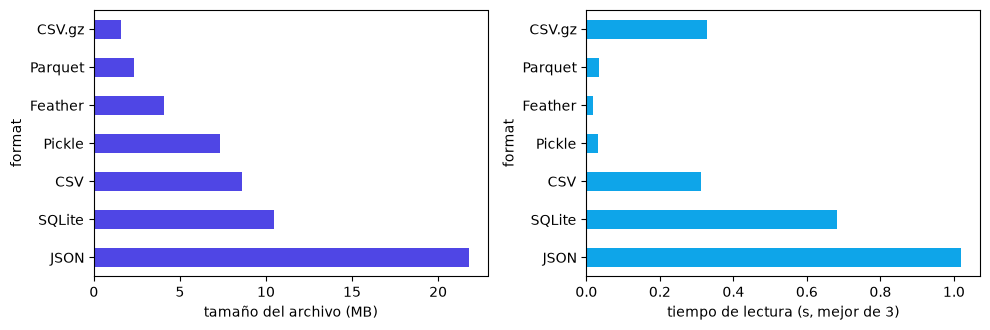

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
results["size_mb"].plot.barh(ax=ax[0], color="#4f46e5"); ax[0].set_xlabel("tamaño del archivo (MB)")
results["read_s"].plot.barh(ax=ax[1], color="#0ea5e9"); ax[1].set_xlabel("tiempo de lectura (s, mejor de 3)")
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.show()

**Cómo leer el resultado.** Los formatos binarios columnares (Parquet, Feather) son los más pequeños y
rápidos *y además* conservan los tipos: las marcas de tiempo siguen siendo marcas de tiempo y las categorías
siguen siendo categorías. CSV y JSON pierden los tipos, así que `timestamp` vuelve como texto y `status` como
cadenas normales, salvo que le digas al lector qué esperar:

In [7]:
back = pd.read_csv(os.path.join(tmp, "data.csv"),
                   parse_dates=["timestamp"], dtype={"status": "category"}, keep_default_na=False)
print(back.dtypes)

timestamp      datetime64[ns]
sensor_id               int64
temperature           float64
status               category
note                   object
dtype: object


## 4. Formatos pequeños de configuración e intercambio
No todo es una tabla. La configuración vive en YAML, TOML o JSON; las API intercambian JSON.

In [8]:
import json, yaml, tomllib

config = {"model": {"name": "baseline", "layers": [64, 32]}, "train": {"epochs": 10, "lr": 0.001}}
as_json = json.dumps(config, indent=2)
as_yaml = yaml.safe_dump(config, sort_keys=False)
print(as_yaml)
assert json.loads(as_json) == yaml.safe_load(as_yaml) == config

toml_text = '[model]\nname = "baseline"\nlayers = [64, 32]\n\n[train]\nepochs = 10\nlr = 0.001\n'
print(tomllib.loads(toml_text) == config)     # TOML: lo que usa pyproject.toml (módulo 07)

model:
  name: baseline
  layers:
  - 64
  - 32
train:
  epochs: 10
  lr: 0.001

True


## 5. Excel
Habitual en entornos de empresa. Lento y frágil con los tipos comparado con Parquet, pero a veces es el
formato que necesita quien va a leer los datos.

In [9]:
path = os.path.join(tmp, "summary.xlsx")
summary_by_status = data.groupby("status", observed=True)["temperature"].agg(["count", "mean", "max"]).round(2)
with pd.ExcelWriter(path) as xl:
    summary_by_status.to_excel(xl, sheet_name="by_status")
    data.head(100).to_excel(xl, sheet_name="sample", index=False)
print(pd.read_excel(path, sheet_name="by_status"))

    status   count   mean    max
0    fault    4045  20.84  37.87
1       ok  180055  21.01  40.97
2  warning   15900  21.01  35.84


## 6. Trampas que conviene conocer
- **Codificaciones.** Los archivos de otros sistemas pueden no estar en UTF-8: `pd.read_csv(path, encoding="latin-1")`.
- **Separadores decimales y de miles.** Los CSV europeos suelen usar `;` y `,`: `pd.read_csv(path, sep=";", decimal=",")`.
- **Fechas.** `01/02/2025` significa días distintos en países distintos; prefiere ISO 8601 (`2025-02-01`).
- **Cargar un pickle ejecuta código.** Está bien para tus propios objetos en caché, pero nunca cargues un
  pickle de una fuente no fiable. La demostración de abajo ejecuta una orden solo con deserializarse:

In [10]:
import pickle

class Malicious:
    def __reduce__(self):                      # le dice a pickle cómo "reconstruir" el objeto
        return (print, ("esto se ejecutó durante pickle.loads: podría haber sido cualquier orden",))

payload = pickle.dumps(Malicious())
pickle.loads(payload)                           # imprime: cargarlo ejecutó código

esto se ejecutó durante pickle.loads: podría haber sido cualquier orden


## ¿Qué formato y cuándo?

| Necesidad | Usa |
|---|---|
| Datos de análisis, cualquier cosa de más de unos pocos MB | **Parquet** (comprimido, tipado, columnar, legible por cualquier herramienta) |
| Intercambio temporal rápido entre Python y R | Feather / Arrow IPC |
| Legible por personas, pequeño, universal | CSV (con tipos explícitos al leer) |
| Datos anidados, API web | JSON |
| Configuración | YAML o TOML |
| Muchos escritores, consultas, transacciones | una base de datos (SQLite en local, PostgreSQL en un servidor) |
| Personas que viven en hojas de cálculo | Excel |
| Guardar en caché tus propios objetos de Python | pickle (solo datos de confianza) |

## Ejercicios
1. Añade una columna `float32` y comprueba qué formatos mantienen `float32` tras el viaje de ida y vuelta.
2. Escribe las lecturas en Parquet particionado por `status` (`partition_cols=["status"]`) y vuelve a leer solo las filas `fault`.
3. Carga el CSV con `usecols=["timestamp", "temperature"]` y compara el tiempo con cargarlo todo.